In [1]:
!pip install -q kagglehub


In [2]:
import kagglehub
from pathlib import Path

dataset_path = Path(
    kagglehub.dataset_download("kaggle/us-consumer-finance-complaints")
)

print("مكان الداتا:", dataset_path)

csv_files = list(dataset_path.rglob("*.csv"))

print("\nملفات CSV الموجودة:")
for i, file in enumerate(csv_files):
    size_mb = file.stat().st_size / (1024 ** 2)
    print(f"{i}: {file.name} — {size_mb:.1f} MB")

if not csv_files:
    print("مفيش ملفات CSV ظاهرة. ابعتلي النتيجة عشان نحدد الخطوة الجاية.")


100%|██████████| 84.5M/84.5M [00:01<00:00, 58.1MB/s]

Extracting files...


مكان الداتا: /root/.cache/kagglehub/datasets/kaggle/us-consumer-finance-complaints/versions/2

ملفات CSV الموجودة:
0: consumer_complaints.csv — 167.3 MB


In [3]:
import pandas as pd

FILE_INDEX = 0

if not csv_files:
    raise ValueError("لم يتم العثور على ملف CSV في الخطوة السابقة.")

if FILE_INDEX >= len(csv_files):
    raise ValueError("رقم الملف غير موجود؛ راجع قائمة الملفات.")

csv_path = csv_files[FILE_INDEX]
print("الملف المختار:", csv_path.name)

# بنقرأ عينة صغيرة الأول بدل ما نحمل الملف كله في الذاكرة.
sample = pd.read_csv(csv_path, nrows=10_000, low_memory=False)

print("\nحجم العينة:", sample.shape)
print("\nأسماء الأعمدة:")
print(sample.columns.tolist())

for column in ["Product", "Consumer complaint narrative"]:
    if column in sample.columns:
        print(f"\nعدد القيم غير الفارغة في {column}:")
        print(sample[column].notna().sum())

if "Product" in sample.columns:
    print("\nفئات المنتجات الأكثر تكرارًا في العينة:")
    print(sample["Product"].value_counts().head(20).to_string())


الملف المختار: consumer_complaints.csv

حجم العينة: (10000, 18)

أسماء الأعمدة:
['date_received', 'product', 'sub_product', 'issue', 'sub_issue', 'consumer_complaint_narrative', 'company_public_response', 'company', 'state', 'zipcode', 'tags', 'consumer_consent_provided', 'submitted_via', 'date_sent_to_company', 'company_response_to_consumer', 'timely_response', 'consumer_disputed?', 'complaint_id']


In [4]:
import pandas as pd
from collections import Counter

product_counts = Counter()
total_rows = 0
rows_with_text = 0

# قراءة الملف على أجزاء لتقليل استهلاك الذاكرة
for chunk in pd.read_csv(
    csv_path,
    usecols=["product", "consumer_complaint_narrative"],
    chunksize=100_000,
    low_memory=False,
):
    total_rows += len(chunk)

    # نستبعد القيم الفارغة والنصوص المكوّنة من مسافات فقط
    text = chunk["consumer_complaint_narrative"]
    has_text = text.notna() & text.fillna("").str.strip().ne("")

    valid = chunk.loc[has_text]
    rows_with_text += len(valid)
    product_counts.update(valid["product"].dropna().value_counts().to_dict())

print(f"إجمالي الصفوف: {total_rows:,}")
print(f"الشكاوى التي تحتوي على نص: {rows_with_text:,}")
print(f"الشكاوى بدون نص: {total_rows - rows_with_text:,}")

print("\nعدد الشكاوى التي تحتوي على نص لكل منتج:")
for product, count in product_counts.most_common():
    print(f"{product}: {count:,}")


إجمالي الصفوف: 555,957
الشكاوى التي تحتوي على نص: 66,806
الشكاوى بدون نص: 489,151

عدد الشكاوى التي تحتوي على نص لكل منتج:
Debt collection: 17,552
Mortgage: 14,919
Credit reporting: 12,526
Credit card: 7,929
Bank account or service: 5,711
Consumer Loan: 3,678
Student loan: 2,128
Prepaid card: 861
Payday loan: 726
Money transfers: 666
Other financial service: 110


In [5]:
import pandas as pd
import re

PRODUCT_MAP = {
    "Credit card": "credit card",
    "Credit reporting": "credit reporting",
    "Debt collection": "debt collection",

    "Mortgage": "mortgages and loans",
    "Consumer Loan": "mortgages and loans",
    "Student loan": "mortgages and loans",
    "Payday loan": "mortgages and loans",

    "Bank account or service": "retail banking",
}

def normalize_text(text):
    # نحافظ على الكلمات والنفي والترقيم.
    # نوحّد المسافات فقط.
    return re.sub(r"\s+", " ", str(text)).strip()

parts = []

for chunk in pd.read_csv(
    csv_path,
    usecols=["product", "consumer_complaint_narrative"],
    chunksize=100_000,
    low_memory=False,
):
    # نحتفظ بالمنتجات التي حددناها وبالشكاوى التي تحتوي على نص
    chunk = chunk[chunk["product"].isin(PRODUCT_MAP)].copy()
    chunk = chunk.dropna(subset=["consumer_complaint_narrative"])

    chunk["text"] = chunk["consumer_complaint_narrative"].map(normalize_text)
    chunk = chunk[chunk["text"].ne("")].copy()
    chunk["label"] = chunk["product"].map(PRODUCT_MAP)

    parts.append(chunk[["product", "text", "label"]])

if not parts:
    raise ValueError("لم يتم العثور على بيانات مناسبة؛ راجع أسماء الأعمدة والمنتجات.")

df = pd.concat(parts, ignore_index=True)

# مفتاح للمقارنة فقط، والنص الأصلي الموحّد المسافات يظل محفوظًا
df["dedup_key"] = df["text"].str.casefold()

print(f"عدد الشكاوى في المنتجات المختارة قبل إزالة التكرار: {len(df):,}")
print("\nتوزيع الفئات قبل إزالة التكرار:")
print(df["label"].value_counts().to_string())

# نص مطابق مرتبط بأكثر من فئة: لا نختار تصنيفًا عشوائيًا له
labels_per_text = df.groupby("dedup_key")["label"].transform("nunique")
conflicting_rows = labels_per_text.gt(1)

print(f"\nصفوف نصوص متطابقة تحمل فئات مختلفة: {conflicting_rows.sum():,}")

# نستبعد كل صفوف النصوص المتعارضة، ثم نحتفظ بنسخة واحدة من كل نص
without_conflicts = df.loc[~conflicting_rows].copy()
duplicate_rows = without_conflicts.duplicated(subset="dedup_key")

print(f"صفوف مكررة إضافية بنفس الفئة: {duplicate_rows.sum():,}")

clean_df = (
    without_conflicts
    .drop_duplicates(subset="dedup_key")
    .reset_index(drop=True)
)

print(f"\nعدد الشكاوى بعد التنظيف: {len(clean_df):,}")
print("\nتوزيع الفئات بعد التنظيف:")
print(clean_df["label"].value_counts().to_string())


عدد الشكاوى في المنتجات المختارة قبل إزالة التكرار: 65,169

توزيع الفئات قبل إزالة التكرار:
label
mortgages and loans    21451
debt collection        17552
credit reporting       12526
credit card             7929
retail banking          5711

صفوف نصوص متطابقة تحمل فئات مختلفة: 41
صفوف مكررة إضافية بنفس الفئة: 1,144

عدد الشكاوى بعد التنظيف: 63,984

توزيع الفئات بعد التنظيف:
label
mortgages and loans    21420
debt collection        17117
credit reporting       11855
credit card             7905
retail banking          5687


In [7]:
from sklearn.model_selection import train_test_split

SEED = 42

# لا نحتاج مفتاح التكرار للتدريب
model_df = clean_df[["text", "label"]].copy()

train_df, remaining_df = train_test_split(
    model_df,
    test_size=0.30,
    stratify=model_df["label"],
    random_state=SEED,
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    stratify=remaining_df["label"],
    random_state=SEED,
)

# التأكد أن نصًا متطابقًا لا يظهر في أكثر من قسم
def text_keys(frame):
    return set(frame["text"].str.casefold())

assert not (text_keys(train_df) & text_keys(val_df))
assert not (text_keys(train_df) & text_keys(test_df))
assert not (text_keys(val_df) & text_keys(test_df))

print("حجم التدريب:", len(train_df))
print("حجم التحقق:", len(val_df))
print("حجم الاختبار:", len(test_df))
print("\n✅ لا توجد نصوص متطابقة بين الأقسام.")

print("\nتوزيع فئات التدريب:")
print(train_df["label"].value_counts().to_string())


حجم التدريب: 44788
حجم التحقق: 9598
حجم الاختبار: 9598

✅ لا توجد نصوص متطابقة بين الأقسام.

توزيع فئات التدريب:
label
mortgages and loans    14994
debt collection        11982
credit reporting        8298
credit card             5533
retail banking          3981


In [8]:
import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score
from sklearn.pipeline import Pipeline

baseline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_features=50_000,
            sublinear_tf=True,
        ),
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=SEED,
        ),
    ),
])

start = time.perf_counter()

# الـTF-IDF يتعلم الكلمات من التدريب فقط
baseline.fit(train_df["text"], train_df["label"])

training_seconds = time.perf_counter() - start
val_predictions = baseline.predict(val_df["text"])

val_macro_f1 = f1_score(
    val_df["label"],
    val_predictions,
    average="macro",
    zero_division=0,
)

print(f"وقت التدريب: {training_seconds:.1f} ثانية")
print(f"Validation Macro F1: {val_macro_f1:.4f}")

print("\nتقرير كل فئة:")
print(
    classification_report(
        val_df["label"],
        val_predictions,
        digits=4,
        zero_division=0,
    )
)


وقت التدريب: 54.2 ثانية
Validation Macro F1: 0.8621

تقرير كل فئة:
                     precision    recall  f1-score   support

        credit card     0.8517    0.7943    0.8220      1186
   credit reporting     0.8667    0.8414    0.8539      1778
    debt collection     0.8451    0.9030    0.8731      2568
mortgages and loans     0.9103    0.9157    0.9130      3213
     retail banking     0.8823    0.8171    0.8484       853

           accuracy                         0.8748      9598
          macro avg     0.8712    0.8543    0.8621      9598
       weighted avg     0.8751    0.8748    0.8744      9598



In [10]:
%pip install -q tensorflow


In [11]:
import numpy as np
import tensorflow as tf

from sklearn.preprocessing import LabelEncoder
from tensorflow.keras import layers

# البيانات لازم تكون اتقسمت في الخلايا السابقة
assert "train_df" in globals(), "شغّل خلايا تحميل وتقسيم البيانات أولًا."
assert "val_df" in globals(), "شغّل خلايا تحميل وتقسيم البيانات أولًا."

tf.keras.utils.set_random_seed(42)

# تحويل أسماء الفئات إلى أرقام
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(train_df["label"])
y_val = label_encoder.transform(val_df["label"])

print("الفئات:", label_encoder.classes_.tolist())
print("GPU متاح:", bool(tf.config.list_physical_devices("GPU")))

# القاموس بيتعلم من بيانات التدريب فقط
MAX_TOKENS = 20_000
MAX_LENGTH = 200

vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=MAX_LENGTH,
)

train_texts = train_df["text"].astype(str).to_numpy()
val_texts = val_df["text"].astype(str).to_numpy()

vectorizer.adapt(train_texts)

x_train = vectorizer(train_texts).numpy()
x_val = vectorizer(val_texts).numpy()

print("شكل التدريب:", x_train.shape)
print("شكل التحقق:", x_val.shape)


الفئات: ['credit card', 'credit reporting', 'debt collection', 'mortgages and loans', 'retail banking']
GPU متاح: False
شكل التدريب: (44788, 200)
شكل التحقق: (9598, 200)


In [12]:
import time

from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping

# إنشاء النموذج
gru_model = Sequential([
    layers.Input(shape=(MAX_LENGTH,), dtype="int64"),

    layers.Embedding(
        input_dim=len(vectorizer.get_vocabulary()),
        output_dim=64,
        mask_zero=True,
    ),

    layers.GRU(64),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(len(label_encoder.classes_), activation="softmax"),
])

gru_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

gru_model.summary()

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

start = time.perf_counter()

history = gru_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=5,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1,
)

gru_training_seconds = time.perf_counter() - start
print(f"\nوقت التدريب: {gru_training_seconds:.1f} ثانية")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,309,445 (5.00 MB)

 Trainable params: 1,309,445 (5.00 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 170s 236ms/step - accuracy: 0.6424 - loss: 0.9266 - val_accuracy: 0.8067 - val_loss: 0.5750
Epoch 2/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 191s 221ms/step - accuracy: 0.8329 - loss: 0.5308 - val_accuracy: 0.8329 - val_loss: 0.5297
Epoch 3/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 156s 222ms/step - accuracy: 0.8727 - loss: 0.4178 - val_accuracy: 0.8566 - val_loss: 0.4591
Epoch 4/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 210s 233ms/step - accuracy: 0.8839 - loss: 0.3815 - val_accuracy: 0.8609 - val_loss: 0.4540
Epoch 5/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 159s 227ms/step - accuracy: 0.9053 - loss: 0.3186 - val_accuracy: 0.8510 - val_loss: 0.4795

وقت التدريب: 885.2 ثانية


In [13]:
import numpy as np
import tensorflow as tf

from sklearn.preprocessing import LabelEncoder
from tensorflow.keras import layers

# البيانات لازم تكون اتقسمت في الخلايا السابقة
assert "train_df" in globals(), "شغّل خلايا تحميل وتقسيم البيانات أولًا."
assert "val_df" in globals(), "شغّل خلايا تحميل وتقسيم البيانات أولًا."

tf.keras.utils.set_random_seed(42)

# تحويل أسماء الفئات إلى أرقام
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(train_df["label"])
y_val = label_encoder.transform(val_df["label"])

print("الفئات:", label_encoder.classes_.tolist())
print("GPU متاح:", bool(tf.config.list_physical_devices("GPU")))

# القاموس بيتعلم من بيانات التدريب فقط
MAX_TOKENS = 20_000
MAX_LENGTH = 200

vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=MAX_LENGTH,
)

train_texts = train_df["text"].astype(str).to_numpy()
val_texts = val_df["text"].astype(str).to_numpy()

vectorizer.adapt(train_texts)

x_train = vectorizer(train_texts).numpy()
x_val = vectorizer(val_texts).numpy()

print("شكل التدريب:", x_train.shape)
print("شكل التحقق:", x_val.shape)


الفئات: ['credit card', 'credit reporting', 'debt collection', 'mortgages and loans', 'retail banking']
GPU متاح: False
شكل التدريب: (44788, 200)
شكل التحقق: (9598, 200)


In [14]:
import time

from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping

# إنشاء النموذج
gru_model = Sequential([
    layers.Input(shape=(MAX_LENGTH,), dtype="int64"),

    layers.Embedding(
        input_dim=len(vectorizer.get_vocabulary()),
        output_dim=64,
        mask_zero=True,
    ),

    layers.GRU(64),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(len(label_encoder.classes_), activation="softmax"),
])

gru_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

gru_model.summary()

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

start = time.perf_counter()

history = gru_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=5,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1,
)

gru_training_seconds = time.perf_counter() - start
print(f"\nوقت التدريب: {gru_training_seconds:.1f} ثانية")


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,309,445 (5.00 MB)

 Trainable params: 1,309,445 (5.00 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 159s 222ms/step - accuracy: 0.6424 - loss: 0.9266 - val_accuracy: 0.8067 - val_loss: 0.5750
Epoch 2/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 154s 220ms/step - accuracy: 0.8329 - loss: 0.5308 - val_accuracy: 0.8329 - val_loss: 0.5297
Epoch 3/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 202s 220ms/step - accuracy: 0.8727 - loss: 0.4178 - val_accuracy: 0.8566 - val_loss: 0.4591
Epoch 4/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 154s 220ms/step - accuracy: 0.8839 - loss: 0.3815 - val_accuracy: 0.8609 - val_loss: 0.4540
Epoch 5/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 153s 219ms/step - accuracy: 0.9053 - loss: 0.3186 - val_accuracy: 0.8510 - val_loss: 0.4795

وقت التدريب: 821.8 ثانية


In [15]:
import numpy as np
from sklearn.metrics import classification_report, f1_score

# التنبؤ على نفس مجموعة التحقق المستخدمة مع الـbaseline
gru_probabilities = gru_model.predict(
    x_val,
    batch_size=128,
    verbose=1,
)

gru_predictions = np.argmax(gru_probabilities, axis=1)

gru_val_f1 = f1_score(
    y_val,
    gru_predictions,
    average="macro",
    zero_division=0,
)

print(f"\nGRU validation macro F1: {gru_val_f1:.4f}")
print(f"GRU training time: {gru_training_seconds:.1f} seconds")

print("\nتقرير كل فئة:")
print(
    classification_report(
        y_val,
        gru_predictions,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        digits=4,
        zero_division=0,
    )
)

print("\nالمقارنة على مجموعة التحقق:")
print(f"TF-IDF + Logistic Regression: {val_macro_f1:.4f}")
print(f"GRU:                          {gru_val_f1:.4f}")


75/75 ━━━━━━━━━━━━━━━━━━━━ 10s 125ms/step

GRU validation macro F1: 0.8459
GRU training time: 821.8 seconds

تقرير كل فئة:
                     precision    recall  f1-score   support

        credit card     0.8174    0.7926    0.8048      1186
   credit reporting     0.8634    0.8352    0.8491      1778
    debt collection     0.8135    0.8933    0.8515      2568
mortgages and loans     0.9262    0.8911    0.9083      3213
     retail banking     0.8335    0.7984    0.8156       853

           accuracy                         0.8609      9598
          macro avg     0.8508    0.8421    0.8459      9598
       weighted avg     0.8627    0.8609    0.8611      9598


المقارنة على مجموعة التحقق:
TF-IDF + Logistic Regression: 0.8621
GRU:                          0.8459


In [16]:
from pathlib import Path

project = Path("/content/drive/MyDrive/complaint_classifier")
backup = Path("/content/complaint_classifier_backup.zip")

print("مجلد المشروع موجود:", project.exists())

for name in ["train.csv", "validation.csv", "test.csv", "baseline.joblib"]:
    print(f"{name} موجود:", (project / name).is_file())

print("ملف النسخة الاحتياطية موجود في الجلسة:", backup.is_file())
print("مجلد MyDrive ظاهر:", Path("/content/drive/MyDrive").exists())


مجلد المشروع موجود: False
train.csv موجود: False
validation.csv موجود: False
test.csv موجود: False
baseline.joblib موجود: False
ملف النسخة الاحتياطية موجود في الجلسة: False
مجلد MyDrive ظاهر: False


In [17]:
from google.colab import drive

drive.mount("/content/drive")


Mounted at /content/drive


In [18]:
from pathlib import Path

project = Path("/content/drive/MyDrive/complaint_classifier")

print("مجلد المشروع موجود:", project.is_dir())

if project.is_dir():
    print("الملفات:")
    for file in sorted(project.iterdir()):
        print("-", file.name)


مجلد المشروع موجود: False


In [19]:
import time
import joblib

from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score
from sklearn.pipeline import Pipeline

# نستخدم نفس بيانات التدريب والتحقق اللي رجعناها
assert "train_df" in globals(), "شغّل خلية تحميل بيانات التدريب أولًا."
assert "val_df" in globals(), "شغّل خلية تحميل بيانات التحقق أولًا."

save_dir = Path("/content/drive/MyDrive/complaint_classifier_restored")

baseline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_features=50_000,
            sublinear_tf=True,
        ),
    ),
    (
        "classifier",
        LogisticRegression(max_iter=1000, random_state=42),
    ),
])

start = time.perf_counter()
baseline.fit(train_df["text"], train_df["label"])
baseline_training_seconds = time.perf_counter() - start

val_predictions = baseline.predict(val_df["text"])
val_macro_f1 = f1_score(
    val_df["label"],
    val_predictions,
    average="macro",
    zero_division=0,
)

print(f"وقت التدريب: {baseline_training_seconds:.1f} ثانية")
print(f"Validation Macro F1: {val_macro_f1:.4f}")
print("\nتقرير الفئات:")
print(classification_report(
    val_df["label"],
    val_predictions,
    digits=4,
    zero_division=0,
))

model_path = save_dir / "baseline.joblib"
joblib.dump(baseline, model_path)

# نتأكد إن الملف قابل للقراءة بعد الحفظ
saved_model = joblib.load(model_path)
print("\n✅ الموديل اتحفظ واتقرأ بنجاح:", model_path)


وقت التدريب: 67.8 ثانية
Validation Macro F1: 0.8621

تقرير الفئات:
                     precision    recall  f1-score   support

        credit card     0.8517    0.7943    0.8220      1186
   credit reporting     0.8667    0.8414    0.8539      1778
    debt collection     0.8451    0.9030    0.8731      2568
mortgages and loans     0.9103    0.9157    0.9130      3213
     retail banking     0.8823    0.8171    0.8484       853

           accuracy                         0.8748      9598
          macro avg     0.8712    0.8543    0.8621      9598
       weighted avg     0.8751    0.8748    0.8744      9598


✅ الموديل اتحفظ واتقرأ بنجاح: /content/drive/MyDrive/complaint_classifier_restored/baseline.joblib


In [20]:
import json
import time

from pathlib import Path
from sklearn.metrics import classification_report, f1_score
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping

save_dir = Path("/content/drive/MyDrive/complaint_classifier_restored")

gru_model = Sequential([
    layers.Input(shape=(MAX_LENGTH,), dtype="int64"),

    layers.Embedding(
        input_dim=len(vectorizer.get_vocabulary()),
        output_dim=64,
        mask_zero=True,
    ),

    layers.GRU(64),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(len(label_encoder.classes_), activation="softmax"),
])

gru_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

start = time.perf_counter()

history = gru_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=5,
    batch_size=64,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True,
        )
    ],
    verbose=1,
)

gru_training_seconds = time.perf_counter() - start

probabilities = gru_model.predict(x_val, batch_size=128, verbose=1)
predictions = np.argmax(probabilities, axis=1)

gru_val_f1 = f1_score(
    y_val,
    predictions,
    average="macro",
    zero_division=0,
)

print(f"\nGRU validation macro F1: {gru_val_f1:.4f}")
print(f"وقت التدريب: {gru_training_seconds:.1f} ثانية")

print(classification_report(
    y_val,
    predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0,
))

# حفظ النموذج وما يلزم لتجهيز النصوص لاحقًا
model_path = save_dir / "gru_model.keras"
gru_model.save(model_path)

with open(save_dir / "gru_vocabulary.json", "w", encoding="utf-8") as f:
    json.dump(vectorizer.get_vocabulary(), f, ensure_ascii=False)

with open(save_dir / "gru_classes.json", "w", encoding="utf-8") as f:
    json.dump(label_encoder.classes_.tolist(), f, ensure_ascii=False)

with open(save_dir / "gru_config.json", "w", encoding="utf-8") as f:
    json.dump({
        "max_tokens": MAX_TOKENS,
        "max_length": MAX_LENGTH,
        "validation_macro_f1": float(gru_val_f1),
        "training_seconds": float(gru_training_seconds),
    }, f, indent=2)

print("\n✅ تم حفظ نموذج GRU والملفات المساعدة في:", save_dir)


Epoch 1/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 170s 229ms/step - accuracy: 0.6387 - loss: 0.9253 - val_accuracy: 0.8252 - val_loss: 0.5442
Epoch 2/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 205s 234ms/step - accuracy: 0.8469 - loss: 0.4902 - val_accuracy: 0.8549 - val_loss: 0.4643
Epoch 3/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 159s 227ms/step - accuracy: 0.8764 - loss: 0.3990 - val_accuracy: 0.8585 - val_loss: 0.4518
Epoch 4/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 203s 229ms/step - accuracy: 0.8963 - loss: 0.3443 - val_accuracy: 0.8569 - val_loss: 0.4631
Epoch 5/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 162s 232ms/step - accuracy: 0.9067 - loss: 0.3067 - val_accuracy: 0.8504 - val_loss: 0.4934
75/75 ━━━━━━━━━━━━━━━━━━━━ 10s 134ms/step

GRU validation macro F1: 0.8399
وقت التدريب: 939.7 ثانية
                     precision    recall  f1-score   support

        credit card     0.7976    0.7740    0.7856      1186
   credit reporting     0.8316    0.8442    0.8378      1778
    debt collection     0.8374    0.8843    0.8602      2568


In [23]:
%pip install -U "transformers>=4.50,<5" "huggingface-hub<1.0" safetensors


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 57.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 113.4 MB/s  0:00:00
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.23.3
    Uninstalling tokenizers-0.23.3:
      Successfully uninstalled tokenizers-0.23.3
  Attempting uninstall: transformers
    Found existing installation: transformers 5.22.1
    Uninstalling transformers-5.22.1:
      Successfully uninstalled transformers-5.22.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [transformers]


In [31]:
import os
import subprocess
import sys

env = os.environ.copy()
env["USE_TF"] = "0"

result = subprocess.run(
    [
        sys.executable,
        "-c",
        (
            "import transformers; "
            "from transformers import AutoTokenizer, "
            "AutoModelForSequenceClassification; "
            "print('IMPORT_OK:', transformers.__version__)"
        ),
    ],
    capture_output=True,
    text=True,
    env=env,
    timeout=60,
)

print("كود الخروج:", result.returncode)
print("\nالناتج:")
print(result.stdout or "(فارغ)")
print("\nرسالة الخطأ:")
print(result.stderr or "(لا يوجد)")


كود الخروج: 0

الناتج:
IMPORT_OK: 4.57.6


رسالة الخطأ:
(لا يوجد)


In [36]:
import os
import subprocess
import sys

env = os.environ.copy()
env["USE_TF"] = "0"

code = """
from pathlib import Path
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

folder = Path("/content/drive/MyDrive/complaint_classifier_restored")

print("استيراد المكتبات: نجح")
print("GPU متاح:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("نوع GPU:", torch.cuda.get_device_name(0))

for name in ["train.csv", "validation.csv", "test.csv"]:
    print(name, "موجود:", (folder / name).is_file())
"""

result = subprocess.run(
    [sys.executable, "-c", code],
    env=env,
    capture_output=True,
    text=True,
    timeout=60,
)

print(result.stdout)
if result.stderr:
    print("الخطأ:", result.stderr)


استيراد المكتبات: نجح
GPU متاح: False
train.csv موجود: True
validation.csv موجود: True
test.csv موجود: True



In [37]:
from google.colab import drive
drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [38]:
import os
import subprocess
import sys

env = os.environ.copy()
env["USE_TF"] = "0"

code = """
from pathlib import Path
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

folder = Path("/content/drive/MyDrive/complaint_classifier_restored")

print("استيراد المكتبات: نجح")
print("GPU متاح:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("نوع GPU:", torch.cuda.get_device_name(0))

for name in ["train.csv", "validation.csv", "test.csv"]:
    print(name, "موجود:", (folder / name).is_file())
"""

result = subprocess.run(
    [sys.executable, "-c", code],
    env=env,
    capture_output=True,
    text=True,
    timeout=60,
)

print(result.stdout)
if result.stderr:
    print("رسالة إضافية:", result.stderr)


استيراد المكتبات: نجح
GPU متاح: False
train.csv موجود: True
validation.csv موجود: True
test.csv موجود: True



In [39]:
%%writefile /content/quick_comparison.py
import os
os.environ["USE_TF"] = "0"

import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

folder = Path("/content/drive/MyDrive/complaint_classifier_restored")
train_df = pd.read_csv(folder / "train.csv")
val_df = pd.read_csv(folder / "validation.csv")

# نفس العينة للموديلين، مع الحفاظ على نسب الفئات تقريبًا
train_sample, _ = train_test_split(
    train_df,
    train_size=2000,
    stratify=train_df["label"],
    random_state=SEED,
)

val_sample, _ = train_test_split(
    val_df,
    train_size=1000,
    stratify=val_df["label"],
    random_state=SEED,
)

classes = sorted(train_sample["label"].unique().tolist())
label_to_id = {name: i for i, name in enumerate(classes)}

print("عدد التدريب:", len(train_sample), flush=True)
print("عدد التحقق:", len(val_sample), flush=True)

# أولًا: baseline على نفس عينة التدريب
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=50_000,
        sublinear_tf=True,
    )),
    ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
])

print("\nتدريب baseline على العينة...", flush=True)
start = time.perf_counter()
baseline.fit(train_sample["text"], train_sample["label"])
baseline_seconds = time.perf_counter() - start

baseline_preds = baseline.predict(val_sample["text"])
baseline_f1 = f1_score(
    val_sample["label"],
    baseline_preds,
    labels=classes,
    average="macro",
    zero_division=0,
)

print(f"Baseline validation macro F1: {baseline_f1:.4f}", flush=True)

# ثانيًا: DistilBERT
model_name = "distilbert/distilbert-base-uncased"
print("\nتحميل DistilBERT؛ قد يستغرق التحميل وقتًا...", flush=True)
tokenizer = AutoTokenizer.from_pretrained(model_name)

class ComplaintDataset(Dataset):
    def __init__(self, frame):
        self.texts = frame["text"].fillna("").astype(str).tolist()
        self.labels = frame["label"].map(label_to_id).tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        item = tokenizer(
            self.texts[index],
            truncation=True,
            max_length=128,
        )
        item["labels"] = self.labels[index]
        return item

collator = DataCollatorWithPadding(tokenizer=tokenizer)

train_loader = DataLoader(
    ComplaintDataset(train_sample),
    batch_size=8,
    shuffle=True,
    collate_fn=collator,
)

val_loader = DataLoader(
    ComplaintDataset(val_sample),
    batch_size=8,
    shuffle=False,
    collate_fn=collator,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("بيئة التدريب:", device, flush=True)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(classes),
    id2label={i: name for i, name in enumerate(classes)},
    label2id=label_to_id,
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)

# دورة واحدة للتجربة الأولية
print("\nتدريب DistilBERT: دورة واحدة...", flush=True)
model.train()
start = time.perf_counter()

for step, batch in enumerate(train_loader, start=1):
    batch = {key: value.to(device) for key, value in batch.items()}

    optimizer.zero_grad()
    output = model(**batch)
    output.loss.backward()
    optimizer.step()

    if step % 25 == 0 or step == len(train_loader):
        print(f"خطوة {step}/{len(train_loader)}", flush=True)

distilbert_seconds = time.perf_counter() - start

print("\nتقييم DistilBERT...", flush=True)
model.eval()
predictions = []
true_labels = []

with torch.no_grad():
    for batch in val_loader:
        batch = {key: value.to(device) for key, value in batch.items()}
        output = model(**batch)
        predictions.extend(output.logits.argmax(dim=1).cpu().tolist())
        true_labels.extend(batch["labels"].cpu().tolist())

distilbert_f1 = f1_score(
    true_labels,
    predictions,
    labels=list(range(len(classes))),
    average="macro",
    zero_division=0,
)

print("\n=== المقارنة الأولية على نفس العينة ===", flush=True)
print(f"Baseline Macro F1:   {baseline_f1:.4f}")
print(f"DistilBERT Macro F1: {distilbert_f1:.4f}")
print(f"Baseline تدريب:      {baseline_seconds:.1f} ثانية")
print(f"DistilBERT تدريب:    {distilbert_seconds:.1f} ثانية")

print("\nتقرير DistilBERT:")
print(classification_report(
    true_labels,
    predictions,
    labels=list(range(len(classes))),
    target_names=classes,
    digits=4,
    zero_division=0,
))

# نحفظ التجربة الأولية في مجلد منفصل
output_dir = folder / "distilbert_cpu_sample"
output_dir.mkdir(parents=True, exist_ok=True)

model.save_pretrained(output_dir)
tokenizer.save_pretrained(output_dir)

with open(output_dir / "sample_results.json", "w", encoding="utf-8") as f:
    json.dump({
        "train_sample_size": len(train_sample),
        "validation_sample_size": len(val_sample),
        "seed": SEED,
        "max_length": 128,
        "epochs": 1,
        "baseline_validation_macro_f1": float(baseline_f1),
        "distilbert_validation_macro_f1": float(distilbert_f1),
        "baseline_training_seconds": float(baseline_seconds),
        "distilbert_training_seconds": float(distilbert_seconds),
    }, f, indent=2)

print("\n✅ حفظنا التجربة الأولية في:", output_dir, flush=True)


Writing /content/quick_comparison.py


In [40]:
!python -u /content/quick_comparison.py


عدد التدريب: 2000
عدد التحقق: 1000

تدريب baseline على العينة...
Baseline validation macro F1: 0.7347

تحميل DistilBERT؛ قد يستغرق التحميل وقتًا...
tokenizer_config.json: 100% 48.0/48.0 [00:00<00:00, 276kB/s]
config.json: 100% 483/483 [00:00<00:00, 2.75MB/s]
vocab.txt: 232kB [00:00, 14.1MB/s]
tokenizer.json: 466kB [00:00, 29.8MB/s]
بيئة التدريب: cpu
model.safetensors: 100% 268M/268M [00:07<00:00, 35.0MB/s]
Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.

تدريب DistilBERT: دورة واحدة...
good
no good
خطوة 25/250
خطوة 50/250
خطوة 75/250
خطوة 100/250
خطوة 125/250
خطوة 150/250
خطوة 175/250
خطوة 200/250
خطوة 225/250
خطوة 250/250

تقييم DistilBERT...

=== المقارنة الأولية على نفس ال

Test Macro F1: 0.8635

تقرير الفئات على مجموعة الاختبار:
                     precision    recall  f1-score   support

        credit card     0.8456    0.7943    0.8191      1186
   credit reporting     0.8685    0.8578    0.8631      1779
    debt collection     0.8486    0.8909    0.8693      2567
mortgages and loans     0.9020    0.9166    0.9092      3213
     retail banking     0.9048    0.8136    0.8568       853

           accuracy                         0.8746      9598
          macro avg     0.8739    0.8546    0.8635      9598
       weighted avg     0.8748    0.8746    0.8742      9598



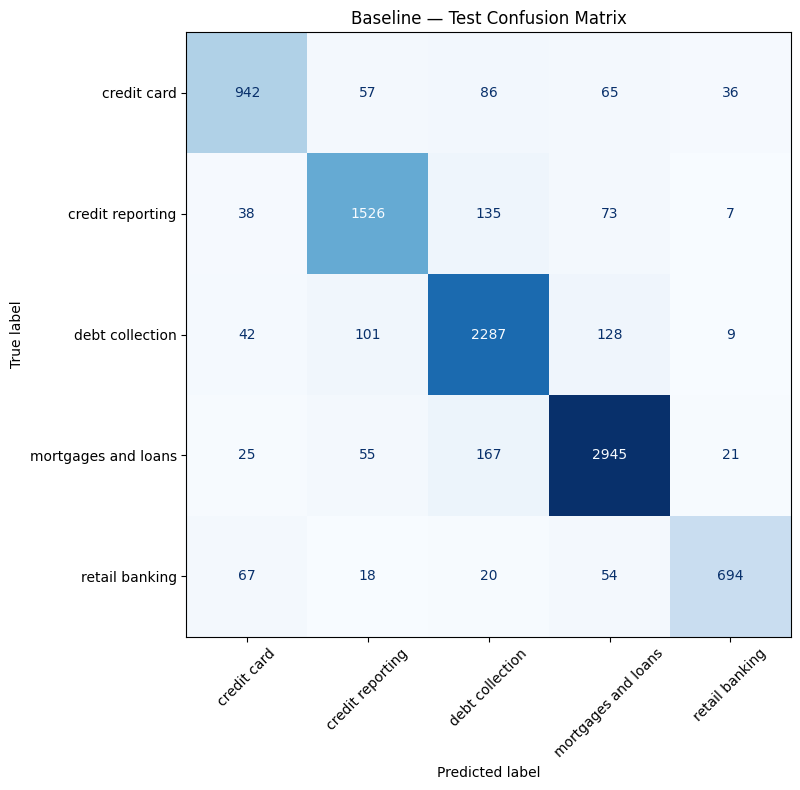


✅ الرسم اتحفظ في: /content/drive/MyDrive/complaint_classifier_restored/baseline_test_confusion_matrix.png
✅ النتائج اتحفظت في: /content/drive/MyDrive/complaint_classifier_restored/baseline_test_results.json


In [41]:
from pathlib import Path
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

folder = Path("/content/drive/MyDrive/complaint_classifier_restored")

# تحميل الموديل المحفوظ ومجموعة الاختبار
baseline = joblib.load(folder / "baseline.joblib")
test_df = pd.read_csv(folder / "test.csv")

test_predictions = baseline.predict(test_df["text"])

test_f1 = f1_score(
    test_df["label"],
    test_predictions,
    average="macro",
    zero_division=0,
)

print(f"Test Macro F1: {test_f1:.4f}")
print("\nتقرير الفئات على مجموعة الاختبار:")
print(classification_report(
    test_df["label"],
    test_predictions,
    digits=4,
    zero_division=0,
))

# رسم مصفوفة الالتباس
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    test_df["label"],
    test_predictions,
    labels=baseline.classes_,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax,
    colorbar=False,
)

ax.set_title("Baseline — Test Confusion Matrix")
plt.tight_layout()

figure_path = folder / "baseline_test_confusion_matrix.png"
plt.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

# حفظ النتائج بدون حفظ نصوص الشكاوى
report = classification_report(
    test_df["label"],
    test_predictions,
    output_dict=True,
    zero_division=0,
)

results_path = folder / "baseline_test_results.json"
with open(results_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("\n✅ الرسم اتحفظ في:", figure_path)
print("✅ النتائج اتحفظت في:", results_path)


In [42]:
from pathlib import Path
import shutil

source = Path("/content/drive/MyDrive/complaint_classifier_restored")
project = Path("/content/drive/MyDrive/consumer-complaint-classifier")

project.mkdir(parents=True, exist_ok=True)
(project / "results").mkdir(exist_ok=True)

# نسخ النتائج والرسم، بدون نسخ بيانات الشكاوى
for filename in [
    "baseline_test_results.json",
    "baseline_test_confusion_matrix.png",
]:
    src = source / filename
    if src.exists():
        shutil.copy2(src, project / "results" / filename)
        print("اتنسخ:", filename)
    else:
        print("مش موجود:", src)

readme = """# Consumer Complaint Classifier

A text-classification project using the Kaggle US Consumer Finance
Complaints dataset. The task assigns a complaint to one of five
product categories.

## Data

- Source: https://www.kaggle.com/datasets/kaggle/us-consumer-finance-complaints
- 63,984 complaints after filtering and exact-text deduplication.
- Split: 44,788 train / 9,598 validation / 9,598 test.
- Duplicate texts with conflicting final labels were excluded.
- Deduplication does not guarantee removal of near-duplicates.

## Categories

Credit card, credit reporting, debt collection, mortgages and loans,
and retail banking. The mortgages-and-loans category combines mortgage,
consumer, student and payday loans in this project.

## Full-data baseline

TF-IDF with Logistic Regression:

| Metric | Score |
|---|---:|
| Validation macro F1 | 0.8621 |
| Test macro F1 | 0.8635 |
| Test accuracy | 0.8746 |

![Test confusion matrix](results/baseline_test_confusion_matrix.png)

## Experiments

- GRU: validation macro F1 of 0.8399 on the full training split.
- Small CPU experiment: baseline 0.7347 and DistilBERT 0.7374
  validation macro F1, trained on the same 2,000 examples and
  evaluated on the same 1,000 examples. DistilBERT used one epoch.

These small-sample scores are not directly comparable to the full-data
scores. GRU and DistilBERT have not been evaluated on the full test set.

## Limitations

- The classifier always chooses one of five categories, even for
  unrelated input; model scores are not guaranteed to be calibrated.
- The data and labels may not represent future complaints or all users.
- Exact deduplication does not eliminate every similar complaint.
- This is a prototype, not a production complaint-routing system.

## Status

The baseline and a Gradio prototype were tested in Colab. Reproducible
application code and dependency instructions still need to be added.
Review the dataset's current terms before redistributing data.
"""

readme_path = project / "README.md"

# لا نستبدل README موجودة من غير تنبيه
if readme_path.exists():
    print("README موجود بالفعل ولم يتم استبداله:", readme_path)
else:
    readme_path.write_text(readme, encoding="utf-8")
    print("✅ اتعمل README:", readme_path)

print("\nمجلد المشروع:", project)
print("محتوياته:", [item.name for item in project.iterdir()])


اتنسخ: baseline_test_results.json
اتنسخ: baseline_test_confusion_matrix.png
✅ اتعمل README: /content/drive/MyDrive/consumer-complaint-classifier/README.md

مجلد المشروع: /content/drive/MyDrive/consumer-complaint-classifier
محتوياته: ['results', 'README.md']


In [44]:
from pathlib import Path
from importlib.metadata import version
import shutil
import joblib

source = Path("/content/drive/MyDrive/complaint_classifier_restored")
project = Path("/content/drive/MyDrive/consumer-complaint-classifier")
artifacts = project / "artifacts"

model_source = source / "baseline.joblib"
model_target = artifacts / "baseline.joblib"

if not model_source.is_file():
    raise FileNotFoundError(f"الموديل مش موجود: {model_source}")

project.mkdir(parents=True, exist_ok=True)
artifacts.mkdir(exist_ok=True)

# لا نستبدل ملفات موجودة من غير ما تعرف
targets = [
    project / "app.py",
    project / "requirements.txt",
    project / ".gitignore",
    model_target,
]

existing = [str(path) for path in targets if path.exists()]
if existing:
    raise FileExistsError(
        "الملفات دي موجودة بالفعل ولم يتم استبدالها:\n"
        + "\n".join(existing)
    )

# نتأكد إن الموديل قابل للتحميل قبل نسخه
model = joblib.load(model_source)
print("الفئات التي يدعمها الموديل:", model.classes_.tolist())

shutil.copy2(model_source, model_target)

app_code = '''from pathlib import Path
import html

import gradio as gr
import joblib

MODEL_PATH = Path(__file__).parent / "artifacts" / "baseline.joblib"

if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Model file not found: {MODEL_PATH}. "
        "Place the trusted baseline.joblib file in the artifacts folder."
    )

# Only load model files from sources you trust.
model = joblib.load(MODEL_PATH)

COLORS = {
    "credit card": "#6366f1",
    "credit reporting": "#38bdf8",
    "debt collection": "#f59e0b",
    "mortgages and loans": "#10b981",
    "retail banking": "#ec4899",
}

ICONS = {
    "credit card": "💳",
    "credit reporting": "📄",
    "debt collection": "📞",
    "mortgages and loans": "🏠",
    "retail banking": "🏦",
}


def classify(text):
    if not text or not text.strip():
        return "<div class='result-card'>Please enter a complaint.</div>"

    probabilities = model.predict_proba([text])[0]
    scores = sorted(
        zip(model.classes_, probabilities),
        key=lambda pair: pair[1],
        reverse=True,
    )

    best_label, best_score = scores[0]
    best_name = html.escape(str(best_label).title())
    best_icon = ICONS.get(best_label, "📌")
    best_color = COLORS.get(best_label, "#8b5cf6")

    rows = []
    for label, score in scores:
        name = html.escape(str(label).title())
        icon = ICONS.get(label, "📌")
        color = COLORS.get(label, "#8b5cf6")
        percentage = float(score) * 100

        rows.append(f"""
        <div class="score-row">
            <span class="score-name">{icon} {name}</span>
            <div class="bar-track">
                <div class="bar-fill"
                     style="width:{percentage:.2f}%;background:{color}">
                </div>
            </div>
            <span class="score-value">{percentage:.1f}%</span>
        </div>
        """)

    return f"""
    <div class="result-card">
        <div class="muted">PREDICTED CATEGORY</div>
        <div class="result-title">{best_icon} {best_name}</div>
        <div class="confidence" style="color:{best_color}">
            Model score: {float(best_score) * 100:.1f}%
        </div>
        <hr>
        {"".join(rows)}
    </div>
    """


css = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
}

.hero {
    background: linear-gradient(110deg, #4f46e5, #9333ea, #db2777);
    border-radius: 20px;
    padding: 28px;
    text-align: center;
    color: white;
    margin-bottom: 20px;
}

.hero h1 { color: white; margin: 0 0 10px; }

.badge {
    display: inline-block;
    background: rgba(255,255,255,.16);
    border: 1px solid rgba(255,255,255,.25);
    border-radius: 20px;
    padding: 6px 12px;
    margin: 5px;
}

.result-card {
    background: #1e293b;
    border: 1px solid #334155;
    border-radius: 18px;
    padding: 24px;
    color: #f8fafc;
}

.muted { color: #94a3b8; font-size: 13px; }
.result-title { font-size: 24px; font-weight: bold; margin: 8px 0; }
.confidence { font-size: 19px; font-weight: bold; }
.result-card hr { border: 0; border-top: 1px solid #475569; margin: 18px 0; }

.score-row {
    display: flex;
    align-items: center;
    gap: 10px;
    margin: 12px 0;
    font-size: 13px;
}

.score-name { width: 155px; flex-shrink: 0; }
.bar-track { flex: 1; background: #0f172a; height: 10px; border-radius: 20px; }
.bar-fill { height: 10px; border-radius: 20px; }
.score-value { width: 45px; text-align: right; }
"""

with gr.Blocks(css=css, theme=gr.themes.Soft()) as app:
    gr.HTML("""
    <div class="hero">
        <h1>📨 Consumer Complaint Classifier</h1>
        <p>Enter an English-language consumer complaint.</p>
        <span class="badge">TF-IDF + Logistic Regression</span>
        <span class="badge">5 product categories</span>
        <span class="badge">Test Macro F1: 0.8635</span>
    </div>
    """)

    with gr.Row():
        with gr.Column():
            complaint = gr.Textbox(
                label="Complaint narrative",
                placeholder="Enter a complaint in English...",
                lines=9,
            )

            with gr.Row():
                submit = gr.Button("Classify", variant="primary")
                clear = gr.ClearButton(value="Clear")

        with gr.Column():
            result = gr.HTML(
                value="<div class='result-card'>Your result will appear here.</div>"
            )

    submit.click(classify, inputs=complaint, outputs=result)
    clear.add([complaint, result])

    gr.Markdown(
        "**Prototype:** The model always selects one of five categories, "
        "even for unrelated text. Scores are not guaranteed to be calibrated."
    )

if __name__ == "__main__":
    app.launch()
'''

(project / "app.py").write_text(app_code, encoding="utf-8")

# نسجل إصدارات المكتبات المستخدمة لحفظ وقراءة الموديل
requirements = [
    f"scikit-learn=={version('scikit-learn')}",
    f"numpy=={version('numpy')}",
    f"scipy=={version('scipy')}",
    f"joblib=={version('joblib')}",
    "gradio==4.44.1",
    "huggingface-hub<1.0",
]

(project / "requirements.txt").write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8",
)

# نستبعد الموديل والبيانات من Git مؤقتًا
(project / ".gitignore").write_text(
    "__pycache__/\\n*.pyc\\nartifacts/*.joblib\\n"
    "train.csv\\nvalidation.csv\\ntest.csv\\n".replace("\\n", "\n"),
    encoding="utf-8",
)

readme_path = project / "README.md"
quickstart = """

## Run the app locally

1. Place the trusted model at `artifacts/baseline.joblib`.
2. Install the dependencies and start the app:

    pip install -r requirements.txt
    python app.py

The model is excluded from this repository pending a distribution decision.
Only load a joblib model file from a trusted source.
Do not enter sensitive personal information into the demo.
"""

with readme_path.open("a", encoding="utf-8") as f:
    f.write(quickstart)

print("\n✅ ملفات المشروع:")
for path in sorted(project.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(project))

print(
    "\nحجم الموديل:",
    round(model_target.stat().st_size / 1024**2, 1),
    "MB",
)


الفئات التي يدعمها الموديل: ['credit card', 'credit reporting', 'debt collection', 'mortgages and loans', 'retail banking']

✅ ملفات المشروع:
- .gitignore
- README.md
- app.py
- artifacts/baseline.joblib
- requirements.txt
- results/baseline_test_confusion_matrix.png
- results/baseline_test_results.json

حجم الموديل: 3.8 MB


In [45]:
import os
import subprocess
import sys
import time
from pathlib import Path
from urllib.request import urlopen

from google.colab.output import eval_js

project = Path("/content/drive/MyDrive/consumer-complaint-classifier")
log_path = Path("/content/complaint_app.log")

env = os.environ.copy()
env["GRADIO_SERVER_NAME"] = "127.0.0.1"
env["GRADIO_SERVER_PORT"] = "7864"

# تشغيل التطبيق المستقل في عملية منفصلة
log_file = open(log_path, "w")
app_process = subprocess.Popen(
    [sys.executable, "-u", str(project / "app.py")],
    cwd=str(project),
    env=env,
    stdout=log_file,
    stderr=subprocess.STDOUT,
)

print("بنجهّز التطبيق...")

ready = False
for _ in range(60):
    if app_process.poll() is not None:
        break

    try:
        with urlopen("http://127.0.0.1:7864", timeout=2):
            ready = True
            break
    except Exception:
        time.sleep(1)

if ready:
    print("✅ التطبيق استجاب. افتحه من الرابط:")
    print(eval_js("google.colab.kernel.proxyPort(7864)"))
else:
    print("التطبيق لم يستجب بعد أو ظهر خطأ. آخر الرسائل:")
    print(log_path.read_text(encoding="utf-8", errors="replace")[-4000:])


بنجهّز التطبيق...
التطبيق لم يستجب بعد أو ظهر خطأ. آخر الرسائل:
handle(scope, receive, send)
  File "/usr/local/lib/python3.13/dist-packages/fastapi/routing.py", line 1281, in handle
    await super().handle(scope, receive, send)
  File "/usr/local/lib/python3.13/dist-packages/starlette/routing.py", line 289, in handle
    await self.app(scope, receive, send)
  File "/usr/local/lib/python3.13/dist-packages/fastapi/routing.py", line 158, in app
    await wrap_app_handling_exceptions(app, request)(scope, receive, send)
  File "/usr/local/lib/python3.13/dist-packages/starlette/_exception_handler.py", line 53, in wrapped_app
    raise exc
  File "/usr/local/lib/python3.13/dist-packages/starlette/_exception_handler.py", line 42, in wrapped_app
    await app(scope, receive, sender)
  File "/usr/local/lib/python3.13/dist-packages/fastapi/routing.py", line 144, in app
    response = await f(request)
               ^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/fastapi/routing

In [46]:
%pip install -q "fastapi==0.112.2" "starlette==0.38.6"


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires fastapi<1,>=0.133, but you have fastapi 0.112.2 which is incompatible.
google-adk 2.7.1 requires starlette<2,>=1.3.1, but you have starlette 0.38.6 which is incompatible.
google-adk 2.7.1 requires websockets<16,>=15.0.1, but you have websockets 12.0 which is incompatible.
python-fasthtml 0.14.18 requires starlette>=1.0.1, but you have starlette 0.38.6 which is incompatible.
